# Задача 4.12
# Встреча при различных временах ожидания

## Условие
У $n$ человек времена ожидания $w_1,\ldots,w_n$ в долях часа. Получить формулы при $n=2,3,4$ и вычислить случай $n=3$, $w=(1/4,1/3,1/2)$. Под встречей понимается **одновременное присутствие всех**.

## Теория с нуля и решение вручную
### 1. Условие общей встречи
Приходы $X_i$ независимы и равномерны на $[0,1]$, $0\le w_i\le1$. Человек $i$ присутствует на $[X_i,X_i+w_i]$. Общая точка этих интервалов существует тогда и только тогда, когда
$$\max_iX_i\le\min_i(X_i+w_i).$$
Ограничение ухода концом часа не влияет на результат, поскольку последний приход не позже 1. При разных ожиданиях одной проверки размаха недостаточно: раньше всех может уйти не первый пришедший.

### 2. Универсальная формула через последнего пришедшего
Пусть последним пришёл человек $j$ в момент $t$. Каждый другой $i$ должен прийти между $\max(0,t-w_i)$ и $t$: длина интервала равна $\min(w_i,t)$. Независимость позволяет перемножить длины; плотность времени $X_j$ равна 1. События с разными последними людьми несовместны с точностью до нулевых совпадений:
$$P_n=\sum_{j=1}^n\int_0^1\prod_{i\ne j}\min(w_i,t)\,dt.$$
Это формула работает без требования сортировки. Для ручного интегрирования разбиваем $[0,1]$ точками $w_i$. На каждом участке каждый минимум равен либо $t$, либо постоянному $w_i$; интегрируется обычная степень: $\int t^kdt=t^{k+1}/(k+1)$.

### 3. Два и три человека
Для двух людей можно вычесть области невстречи:
$$P_2=1-\frac{(1-w_1)^2}2-\frac{(1-w_2)^2}2.$$
Для трёх сначала переобозначим времена так, чтобы $a\le b\le c$. Формулы из листка используют именно этот порядок; без него они могут дать неверный ответ. Обозначим $J(u,v)=\int_0^1\min(u,t)\min(v,t)dt$ при $u\le v$. Тогда
$$J(u,v)=\int_0^ut^2dt+\int_u^vut\,dt+\int_v^1uv\,dt=uv-\frac{uv^2}2-\frac{u^3}6.$$
Складывая $J(a,b)+J(a,c)+J(b,c)$, получаем
$$P_3=ab+ac+bc-\frac12(ab^2+ac^2+bc^2)-\frac{a^3}3-\frac{b^3}6.$$
При $a=1/4,b=1/3,c=1/2$:
$$ab+ac+bc=\frac38,\quad\frac{ab^2+ac^2+bc^2}{2}=\frac{25}{288},\quad\frac{a^3}3=\frac1{192},\quad\frac{b^3}6=\frac1{162}.$$
Поэтому
$$P_3=\frac38-\frac{25}{288}-\frac1{192}-\frac1{162}=\frac{1435}{5184}\approx0.27681327.$$

### 4. Четыре человека
Пусть $a\le b\le c\le d$. Для трёх множителей при $u\le v\le z$:
$$K(u,v,z)=\int_0^ut^3dt+\int_u^vut^2dt+\int_v^zuvt\,dt+\int_z^1uvz\,dt=uvz-\frac{uvz^2}2-\frac{uv^3}6-\frac{u^4}{12}.$$
Теперь $P_4=K(a,b,c)+K(a,b,d)+K(a,c,d)+K(b,c,d)$, откуда
$$P_4=abc+abd+acd+bcd-\frac{d^2}{2}(ab+ac+bc)-\frac{c^3}{6}(a+b)-\frac{abc^2}{2}-\frac{ab^3}{3}-\frac{a^4}{4}-\frac{b^4}{12}.$$
Это и есть формула листка при упорядоченных ожиданиях. Если все ожидания равны $q$, она превращается в $4q^3-3q^4$, как в 4.11.

### 5. Переход к коду
`Fraction` сохраняет точность рациональных вычислений. Реализуем непосредственно формулы $J$ и $K$, а эксперимент проверяет пересечение интервалов. Для $n=2$ и $n=4$, где конкретных чисел нет, приводим явно указанные примеры; все формулы даны в общем виде.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Ожидания: [Fraction(1, 6), Fraction(1, 5)] Точная вероятность: 599/1800
Общая встреча 2 лиц: успехов 49818, знаменатель 150000
  частота = 0.33212000; ориентир 95%: [0.32973654; 0.33450346]
  теория = 0.33277778; разность = -0.00065778


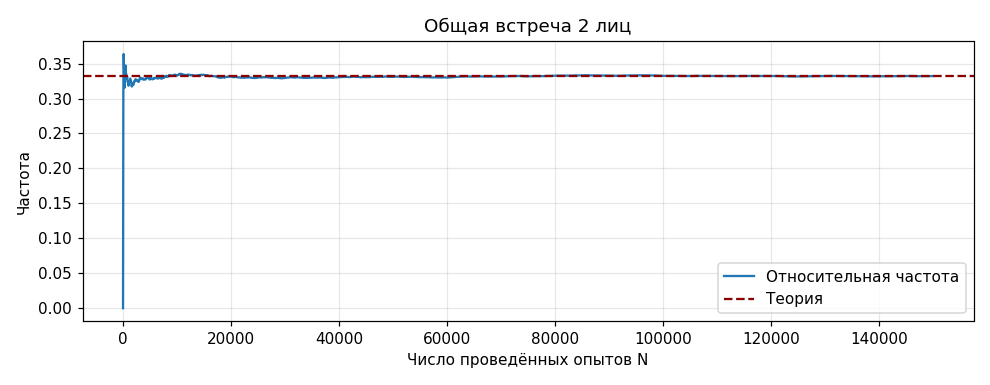

Ожидания: [Fraction(1, 4), Fraction(1, 3), Fraction(1, 2)] Точная вероятность: 1435/5184
Общая встреча 3 лиц: успехов 41717, знаменатель 150000
  частота = 0.27811333; ориентир 95%: [0.27584579; 0.28038088]
  теория = 0.27681327; разность = +0.00130006


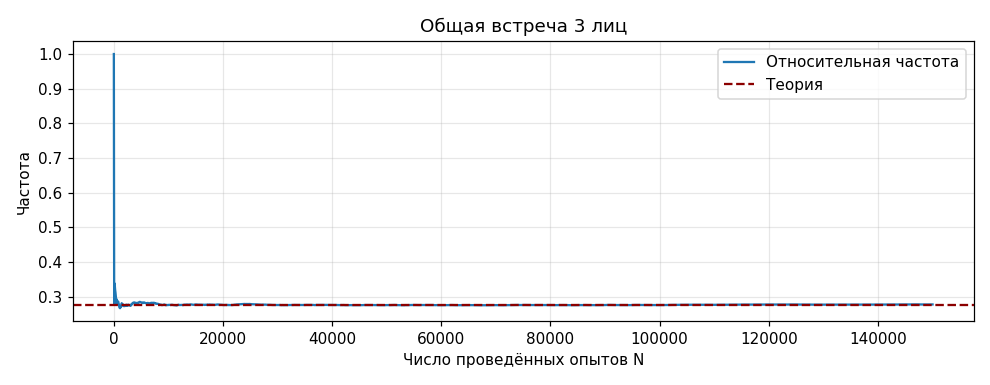

Ожидания: [Fraction(1, 5), Fraction(1, 3), Fraction(1, 2), Fraction(3, 4)] Точная вероятность: 807931/4860000
Общая встреча 4 лиц: успехов 24745, знаменатель 150000
  частота = 0.16496667; ориентир 95%: [0.16308839; 0.16684495]
  теория = 0.16624095; разность = -0.00127428


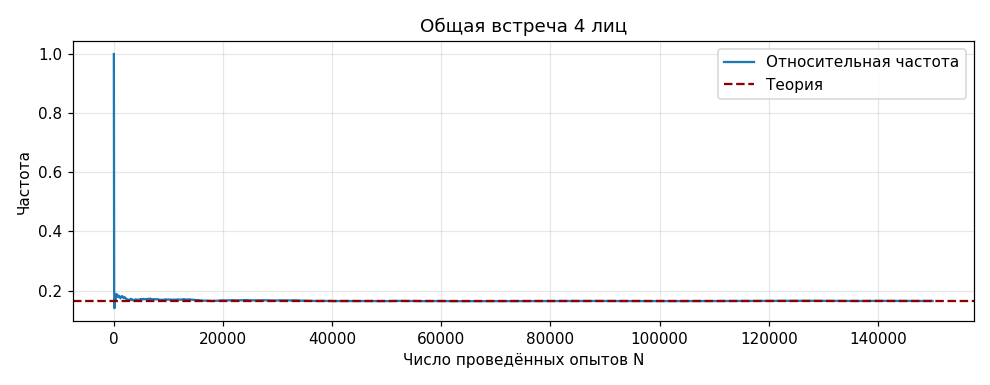

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

def probability(waiting):
    w = sorted(Fraction(x) for x in waiting)
    if any(x < 0 or x > 1 for x in w):
        raise ValueError('Ожидания должны быть от 0 до 1')
    if len(w) == 2:
        a, b = w
        return 1-(1-a)**2/2-(1-b)**2/2
    if len(w) == 3:
        a, b, c = w
        def J(u, v):
            return u*v-u*v**2/2-u**3/6
        return J(a,b)+J(a,c)+J(b,c)
    if len(w) == 4:
        a,b,c,d = w
        def K(u,v,z):
            return u*v*z-u*v*z**2/2-u*v**3/6-u**4/12
        return K(a,b,c)+K(a,b,d)+K(a,c,d)+K(b,c,d)
    raise ValueError('В этой задаче рассматриваем n=2,3,4')

N = 150_000
examples = [[Fraction(1,6), Fraction(1,5)],
            [Fraction(1,4), Fraction(1,3), Fraction(1,2)],
            [Fraction(1,5), Fraction(1,3), Fraction(1,2), Fraction(3,4)]]
for waiting in examples:
    exact = probability(waiting)
    print('Ожидания:', waiting, 'Точная вероятность:', exact)
    arrivals = rng.random((N, len(waiting)))
    departures = arrivals + np.array([float(w) for w in waiting])
    # Теория 1: последний приход должен быть не позже первого ухода.
    meeting = np.max(arrivals, axis=1) <= np.min(departures, axis=1)
    report(meeting, f'Общая встреча {len(waiting)} лиц', exact)
